<a href="https://colab.research.google.com/github/Tonikaneprv/PDA/blob/lab3/%D0%92%D0%B5%D0%B4%D0%B5%D1%80%D0%BD%D0%B8%D0%BA%D0%BE%D0%B2%D0%B0_%22PDA_26_27_%D0%9B%D0%A03_%D0%9E%D0%B1%D0%B5%D1%81%D0%BF%D0%B5%D1%87%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BA%D0%B0%D1%87%D0%B5%D1%81%D1%82%D0%B2%D0%B0_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [1]:
import re
import numpy as np
import pandas as pd
import missingno as msno
from matplotlib import pyplot as plt
import seaborn as sns

В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [5]:
DATA_PATH = '/content/monster_com_job_sample.csv'

df = pd.read_csv(DATA_PATH)

pd.set_option('display.max_colwidth', 60)
pd.set_option('display.max_columns', None)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#E5E5E5', 'axes.axisbelow': True})
C_MAIN, C_ACCENT, C_MUTED = '#2a78d6', '#eb6834', '#a8a8a8'

print('Размер датасета:', df.shape)
df.info()
df.sample(5, random_state=42)

Размер датасета: (22000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   country          22000 non-null  object
 1   country_code     22000 non-null  object
 2   date_added       122 non-null    object
 3   has_expired      22000 non-null  object
 4   job_board        22000 non-null  object
 5   job_description  22000 non-null  object
 6   job_title        22000 non-null  object
 7   job_type         20372 non-null  object
 8   location         22000 non-null  object
 9   organization     15133 non-null  object
 10  page_url         22000 non-null  object
 11  salary           3446 non-null   object
 12  sector           16806 non-null  object
 13  uniq_id          22000 non-null  object
dtypes: object(14)
memory usage: 2.3+ MB


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,NaN,No,jobs.monster.com,The QC Lead position requires an understanding of food s...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lead-Job-Sant...,NaN,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,NaN,No,jobs.monster.com,JOB DESCRIPTION ...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Sunset-Point...,NaN,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,NaN,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation PR will b...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundation-pr-job-...,NaN,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,NaN,No,jobs.monster.com,GroundskeeperWest Knox Apart need a F/T Groundskeeper. D...,Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",NaN,http://jobview.monster.com/Groundskeeper-Job-Knoxville-T...,NaN,NaN,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,NaN,No,jobs.monster.com,Combined Insurance is seeking Sales Agents to join our f...,Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Knoxville-TN-...,NaN,NaN,ec59e3f419b851259632b757183d7365


**Задание**

Составьте таблицу, в которой будет содержаться название столбца, тип данных в нем и краткое описание проблем, которые вы заметили при первом взгляде на данные.


Название столбца | Тип данных | Проблемы
--- | --- | ---
```country``` |
```country_code``` |
```date_added``` |
```has_expired``` |
```job_board``` |
```job_description``` |
```job_title``` |
```job_type``` |
```location``` |
```organization``` |
```page_url``` |
```salary``` |
```sector``` |
```uniq_id``` |

### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью столбчатой диаграммы. Для удобства можно воспользоваться модулем `missingno`.


,всего ячеек,пустых ячеек,"доля пустых, %"
country,22000,0,0.00
country_code,22000,0,0.00
date_added,22000,21878,99.45
has_expired,22000,0,0.00
job_board,22000,0,0.00
job_description,22000,0,0.00
job_title,22000,0,0.00
job_type,22000,1628,7.40
location,22000,0,0.00
organization,22000,6867,31.21


Строк, где пусто более 75% ячеек: 0
Максимум пустых ячеек в одной строке: 5 из 14


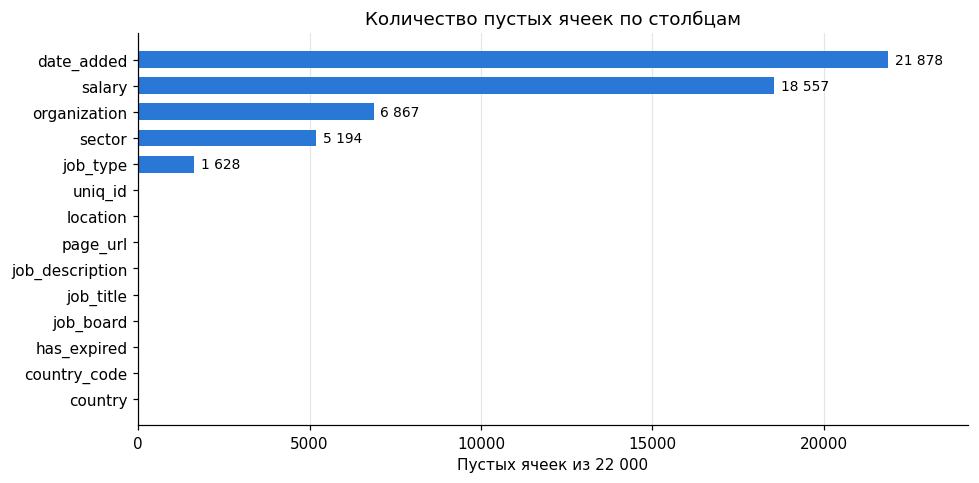

In [6]:
is_empty = df.apply(lambda s: s.isna() | s.str.strip().eq(''))

missing = pd.DataFrame({
    'всего ячеек': len(df),
    'пустых ячеек': is_empty.sum(),
})
missing['доля пустых, %'] = (missing['пустых ячеек'] / missing['всего ячеек'] * 100).round(2)
display(missing)

rows_75 = (is_empty.mean(axis=1) > 0.75).sum()
print('Строк, где пусто более 75% ячеек:', rows_75)
print('Максимум пустых ячеек в одной строке:', is_empty.sum(axis=1).max(), 'из', df.shape[1])

order = missing.sort_values('пустых ячеек')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(order.index, order['пустых ячеек'], color=C_MAIN, height=0.65)
ax.set_title('Количество пустых ячеек по столбцам')
ax.set_xlabel(f'Пустых ячеек из {len(df):,}'.replace(',', ' '))
ax.grid(axis='y', visible=False)
for y, v in enumerate(order['пустых ячеек']):
    if v:
        ax.text(v + 200, y, f'{v:,}'.replace(',', ' '), va='center', fontsize=9)
ax.set_xlim(0, len(df) * 1.1)
plt.tight_layout()
plt.show()

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [7]:
print('Размер исходного датасета:', df.shape)
print('После удаления всех строк с пропусками:', df.dropna().shape)

for cols in (['date_added'], ['salary'], ['date_added', 'salary']):
    rest = df.drop(columns=cols).dropna()
    print(f'Если не учитывать {cols}: останется строк {len(rest)}')

Размер исходного датасета: (22000, 14)
После удаления всех строк с пропусками: (5, 14)
Если не учитывать ['date_added']: останется строк 1919
Если не учитывать ['salary']: останется строк 113
Если не учитывать ['date_added', 'salary']: останется строк 11847


### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [8]:
nunique = df.nunique().sort_values()
display(nunique.to_frame('уникальных значений'))
single_value = nunique[nunique == 1].index.tolist()
print('Одно значение на весь столбец:', single_value)
display(df[single_value].drop_duplicates())

columns = [c for c in df.columns if c not in single_value]
values = {c: set(df[c].dropna().str.strip()) - {''} for c in columns}
pairs = []
for i, a in enumerate(columns):
    for b in columns[i + 1:]:
        common = values[a] & values[b]
        if common:
            pairs.append({'столбец 1': a, 'столбец 2': b,
                          'общих значений': len(common),
                          'строк в столбце 1': df[a].str.strip().isin(common).sum(),
                          'строк в столбце 2': df[b].str.strip().isin(common).sum(),
                          'примеры': sorted(common, key=len)[:3]})
display(pd.DataFrame(pairs).sort_values('общих значений', ascending=False))

LOCATION_LIKE = r"[A-Z][\w .'\-]+,\s*[A-Z]{2}(?:\s+\d{5})?"
LEVELS = r'Experienced|Entry Level|Manager \(|Executive \(|Student'
INDUSTRY_WORDS = r'Services|Manufacturing|Retail|Construction|Healthcare|Other/Not Classified|^All$|Insurance|Computer|Biotechnology'
checks = {
    'organization: похоже на отрасль, а не компанию': df['organization'].str.contains(INDUSTRY_WORDS, na=False),
    'organization: указан город и штат': df['organization'].str.fullmatch(LOCATION_LIKE, na=False),
    'sector: уровень должности, а не сфера': df['sector'].str.contains(LEVELS, na=False),
    'sector: текст длиннее 100 символов': df['sector'].str.len().gt(100),
    'location: текст длиннее 60 символов': df['location'].str.len().gt(60),
    'location: контакты (Contact/Phone/Fax/Address)': df['location'].str.match(r'(?:Contact name|Phone|Fax|Address)\b', na=False),
    'salary: нет суммы, только текст': df['salary'].str.contains(r'[A-Za-z]', na=False) & ~df['salary'].str.contains(r'\d', na=False),
    'job_title: в заголовке остался CSS/JS-код': df['job_title'].str.contains(r'body \{|var M', na=False),
}
display(pd.Series({k: int(v.sum()) for k, v in checks.items()}).to_frame('строк'))

,уникальных значений
country,1
country_code,1
has_expired,1
job_board,1
job_type,39
date_added,78
sector,163
organization,738
salary,1737
location,8423


Одно значение на весь столбец: ['country', 'country_code', 'has_expired', 'job_board']


,country,country_code,has_expired,job_board
0,United States of America,US,No,jobs.monster.com


,столбец 1,столбец 2,общих значений,строк в столбце 1,строк в столбце 2,примеры
1,job_description,location,849,910,905,[Job Description Job #: 671297Please email resumes to c...
5,location,organization,126,4097,227,"[Omaha, NE, Plano, TX, Albany, NY]"
2,job_title,location,12,29,24,"[Recruiter, Job Details, RF Engineer]"
6,organization,sector,2,1082,24,"[Retail, Electrical/Electronics EngineeringIndustrial/Ma..."
0,job_description,job_title,1,31,31,[Please apply only if you are qualified.]
4,job_type,organization,1,6617,9,[Full Time Employee]
3,job_type,location,1,6617,9,[Full Time Employee]


,строк
"organization: похоже на отрасль, а не компанию",11874
organization: указан город и штат,299
"sector: уровень должности, а не сфера",6838
sector: текст длиннее 100 символов,17
location: текст длиннее 60 символов,1400
location: контакты (Contact/Phone/Fax/Address),695
"salary: нет суммы, только текст",358
job_title: в заголовке остался CSS/JS-код,1112


### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [9]:
print('uniq_id: уникальных значений', df['uniq_id'].nunique(), 'из', len(df))
all_unique = [c for c in df.columns if df[c].nunique() == len(df)]
print('Столбцы, где все значения различны:', all_unique)

other_columns = [c for c in df.columns if c not in all_unique]
dup_extra = df.duplicated(subset=other_columns, keep='first')
dup_all = df.duplicated(subset=other_columns, keep=False)
print('Строк-дубликатов (без первых вхождений):', dup_extra.sum(), f'({dup_extra.mean():.1%})')
print('Строк, входящих в группы дубликатов:', dup_all.sum())
print('Групп дубликатов:', df[dup_all].groupby(other_columns, dropna=False).ngroups)

url_base = df['page_url'].str.split('?').str[0]
print('Повторов page_url без параметров запроса:', url_base.duplicated().sum())

example_title = df.loc[dup_all, 'job_title'].iloc[0]
display(df.loc[dup_all & df['job_title'].eq(example_title), ['job_title', 'location', 'page_url', 'uniq_id']].head(3))

uniq_id: уникальных значений 22000 из 22000
Столбцы, где все значения различны: ['page_url', 'uniq_id']
Строк-дубликатов (без первых вхождений): 1168 (5.3%)
Строк, входящих в группы дубликатов: 2078
Групп дубликатов: 910
Повторов page_url без параметров запроса: 506


,job_title,location,page_url,uniq_id
17,Pest Control Technician – Field Service Rep (Entry Level...,"Denver, CO",http://jobview.monster.com/Pest-Control-Technician-%E2%8...,8d8f39de4a07929a92c2e6dd7a72a0af
8404,Pest Control Technician – Field Service Rep (Entry Level...,"Denver, CO",http://jobview.monster.com/pest-control-technician-%E2%8...,678061d7935db10ec06dcd3a404a8b55


# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

Город отделён от приклеенного текста в строках: 24 | примеры: ['Averitt ExpressChattanooga', 'Crete CarrierChattanooga', 'Equity TransportationChattanooga', 'Highway TransportChattanooga']


,строк,"доля, %"
loc_format,,
"Город, штат индекс",11343,51.56
"Город, штат",7170,32.59
Формат не определён,2551,11.60
Город индекс,331,1.50
Только индекс,254,1.15
Только штат,230,1.05
ГородШтат (слитно),94,0.43
Город штат,15,0.07
Только город,11,0.05


,примеры
"Город, штат индекс","Madison, WI 53702 | Madison, WI 53708"
"Город, штат","Dixon, CA | Camphill, PA"
Формат не определён,DePuy Synthes Companies is a member of J | Contact name ...
Город индекс,Wadesboro 28170 | La Porte 46350
Только индекс,46052 | 19904
Только штат,WI | CA
ГородШтат (слитно),DallasTX | IndianapolisIN
Город штат,Parsippany-Troy Hills NJ | Parsippany-Troy Hills NJ
Только город,Lynnwood | Lynnwood
"Город, индекс","New York, 10019"


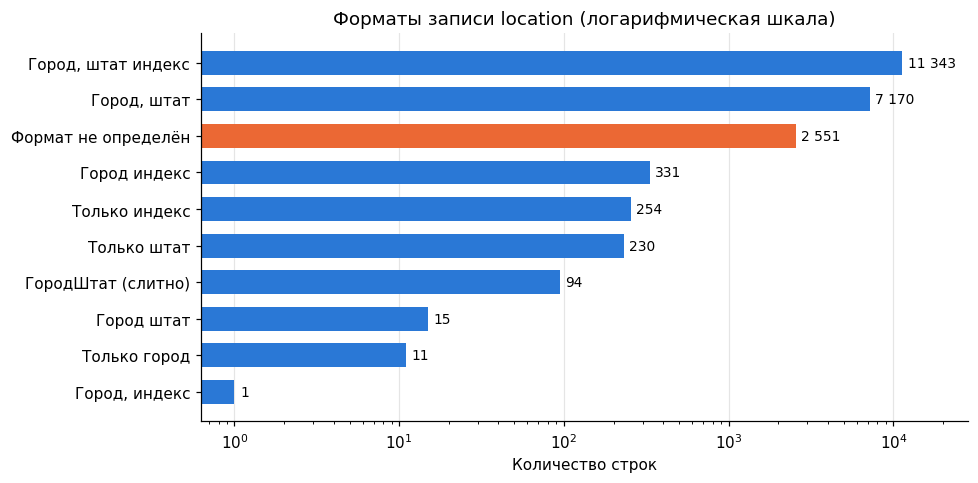

In [10]:
STATE = (r'(?:A[LKZR]|C[AOT]|D[EC]|FL|G[AU]|HI|I[ADLN]|K[SY]|LA|M[ADEINOST]|N[CDEHJMVY]'
         r'|O[HKR]|P[AR]|RI|S[CD]|T[NX]|UT|V[AIT]|W[AIVY])')
ZIP = r'\d{5}(?:-\d{4})?'
CITY = r"(?!(?:Address|Contact|Phone|Fax|Company|Location|Job)\b)[A-Za-z][A-Za-z.'\- ]*?"

LOCATION_PATTERNS = {
    'Город, штат индекс': rf'(?P<city>{CITY})(?:,\s*[A-Za-z. ]+)?,\s*(?P<state>{STATE})\s+(?P<zip>{ZIP})',
    'Город, штат':        rf'(?P<city>{CITY}),\s*(?P<state>{STATE})',
    'Город штат':         rf'(?P<city>{CITY})\s+(?P<state>{STATE})',
    'ГородШтат (слитно)': rf"(?P<city>[A-Za-z.'\- ]*[a-z.])(?P<state>{STATE})",
    'Город, индекс':      rf'(?P<city>{CITY}),\s*(?P<zip>{ZIP})',
    'Город индекс':       rf'(?P<city>{CITY})\s+(?P<zip>{ZIP})',
    'Штат индекс':        rf'(?P<state>{STATE})\s+(?P<zip>{ZIP})',
    'Только штат':        rf'(?P<state>{STATE})',
    'Только индекс':      rf'(?P<zip>{ZIP})',
}
LOCATION_PATTERNS = {name: re.compile(p) for name, p in LOCATION_PATTERNS.items()}
UNKNOWN = 'Формат не определён'
MAX_LOCATION_LEN = 60


def clean_text(s):

    return s.str.replace('\xa0', ' ', regex=False).str.strip()


def parse_location(text):
    if len(text) <= MAX_LOCATION_LEN:
        for name, pattern in LOCATION_PATTERNS.items():
            m = pattern.fullmatch(text)
            if m:
                d = m.groupdict()
                return name, d.get('city'), d.get('state'), d.get('zip')
    return UNKNOWN, None, None, None

GLUE = re.compile(r'(?<=[a-z])(?<!\bMc)(?<!\bMac)(?<!\bDe)(?<!\bDu)(?<!\bLa)(?<!\bLe)(?=[A-Z][a-z])|(?<=[A-Z]{2}\.)(?=[A-Z][a-z])|(?<=LLC)(?=[A-Z])|(?<=Inc\.)(?=[A-Z])')


def split_glued_city(raw):
    return GLUE.split(raw.strip())[-1].strip() or None


location_clean = clean_text(df['location'])
parsed = location_clean.map(parse_location)
loc = pd.DataFrame(parsed.tolist(), index=df.index, columns=['loc_format', 'city', 'state', 'zip'])
city_raw = loc['city'].str.strip()
loc['city'] = city_raw.map(split_glued_city, na_action='ignore')
glued = city_raw.notna() & city_raw.ne(loc['city'])
print('Город отделён от приклеенного текста в строках:', glued.sum(), '| примеры:', sorted(set(city_raw[glued]))[:4])

known_cities = set(loc['city'].dropna().str.lower())
only_city = loc['loc_format'].eq(UNKNOWN) & location_clean.str.fullmatch(CITY, na=False) & location_clean.str.lower().isin(known_cities)
loc.loc[only_city, 'loc_format'] = 'Только город'
loc.loc[only_city, 'city'] = location_clean[only_city]

format_counts = loc['loc_format'].value_counts()
display(pd.DataFrame({'строк': format_counts, 'доля, %': (format_counts / len(df) * 100).round(2)}))

display(pd.Series({name: ' | '.join(location_clean[loc['loc_format'].eq(name)].head(2).str[:40]) for name in format_counts.index}).to_frame('примеры'))

order = format_counts.sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [C_ACCENT if name == UNKNOWN else C_MAIN for name in order.index]
ax.barh(order.index, order.values, color=colors, height=0.65)
ax.set_xscale('log')
ax.set_title('Форматы записи location (логарифмическая шкала)')
ax.set_xlabel('Количество строк')
ax.grid(axis='y', visible=False)
for y, v in enumerate(order.values):
    ax.text(v * 1.08, y, f'{v:,}'.replace(',', ' '), va='center', fontsize=9)
ax.set_xlim(right=order.max() * 2.5)
plt.tight_layout()
plt.show()

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [11]:
is_unknown = loc['loc_format'].eq(UNKNOWN)
df_unknown_location = df[is_unknown].copy()
df_location = df[~is_unknown].copy()
df_location[['city', 'state', 'zip']] = loc.loc[~is_unknown, ['city', 'state', 'zip']]

print('Определён формат:', len(df_location), '| не определён:', len(df_unknown_location))
display(df_location[['location', 'city', 'state', 'zip']].sample(8, random_state=7))
display(df_location[['city', 'state', 'zip']].notna().sum().to_frame('заполнено'))

Определён формат: 19449 | не определён: 2551


,location,city,state,zip
2412,"New York, NY 10175",New York,NY,10175
5845,"Chicago, IL 60606",Chicago,IL,60606
12016,"Falls Church, VA",Falls Church,VA,None
10037,"Indianapolis, IN",Indianapolis,IN,None
11594,"Usa, AL 36602",Usa,AL,36602
8958,"Chattanooga, TN",Chattanooga,TN,None
9960,"Salt Lake City, UT 84116",Salt Lake City,UT,84116
10256,"Conshohocken, PA",Conshohocken,PA,None


,заполнено
city,18965
state,18852
zip,11929


#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [14]:
unknown_text = clean_text(df_unknown_location['location'])
kinds = [
    ('Контакты (Contact/Phone/Fax/Address)', unknown_text.str.match(r'(?:Contact name|Phone|Fax|Address)\b')),
    ('Заглушка «Location:» без значения', unknown_text.str.fullmatch(r'Location\s*:?')),
    ('Фрагмент описания (> 60 символов)', unknown_text.str.len() > MAX_LOCATION_LEN),
]
kind = pd.Series('Прочий короткий текст (должность, компания и т. п.)', index=unknown_text.index)
for name, mask in reversed(kinds):
    kind[mask] = name
display(kind.value_counts().to_frame('строк'))
display(unknown_text[kind.str.startswith('Прочий')].value_counts().head(10).to_frame('строк'))

url_parts = df['page_url'].str.extract(rf'(?i).*-job-(?P<city>[a-z0-9\-]+?)-(?P<state>[a-z]{{2}})-us-\d+')
url_parts['city'] = url_parts['city'].str.replace('-', ' ', regex=False).str.title()
url_parts['state'] = url_parts['state'].str.upper()
url_parts.loc[~url_parts['state'].fillna('').str.fullmatch(STATE), ['city', 'state']] = None

title_city = df['job_title'].str.extract(r" Job in ([A-Za-z.'\- ]+?)(?:\s{2,}|$)")[0].str.strip()
title_city = title_city.where(title_city.str.contains('[A-Za-z]{3}', na=False) & ~title_city.str.fullmatch(STATE, case=False, na=False))


known = loc[~is_unknown]
url_k, title_k = url_parts.loc[known.index], title_city.loc[known.index]
same_state = (url_k['state'] == known['state'])[known['state'].notna() & url_k['state'].notna()]
same_url_city = (url_k['city'].str.lower() == known['city'].str.lower())[known['city'].notna() & url_k['city'].notna()]
same_title = (title_k.str.lower() == known['city'].str.lower())[known['city'].notna() & title_k.notna()]
print(f'Совпадение со столбцом location: штат из URL {same_state.mean():.1%} (n={len(same_state)}), '
      f'город из URL {same_url_city.mean():.1%} (n={len(same_url_city)}), '
      f'город из job_title {same_title.mean():.1%} (n={len(same_title)})')

TEXT_ADDRESS = re.compile(rf"(?P<city>[A-Za-z.'\- ]{{2,40}}),?\s+(?P<state>{STATE})\.?(?:\s+US)?,?\s+(?P<zip>\d{{5}})(?:-?\d{{4}})?\b")
TEXT_CITY_STATE = re.compile(rf"(?P<city>[A-Z][A-Za-z.'\- ]{{1,30}}),\s*(?P<state>{STATE})\b")


TEXT_REVERSED = re.compile(rf"(?:US-)?(?P<state>{STATE})[-,]\s*(?P<city>[A-Za-z.' ]+)", re.I)
TEXT_ANY_CASE = re.compile(rf"(?P<city>[A-Za-z.' ]+),\s*(?P<state>{STATE})\s+(?P<zip>\d{{5}})", re.I)
TEXT_STATE_END = re.compile(rf",\s*(?P<state>{STATE})\s*$")
ZIP_AT_END = re.compile(r'Address\b.*?\b(\d{5})(?:-?\d{4})?\s*$')


def text_city(raw):

    city = split_glued_city(re.sub(r'^.*\bAddress\s+', '', raw))
    return city.title() if city and city.islower() else city


def parse_text_address(text):
    for pattern in (TEXT_ANY_CASE, TEXT_REVERSED):
        m = pattern.fullmatch(text)
        if m:
            return text_city(m['city']), m['state'].upper(), m.groupdict().get('zip')
    m = TEXT_ADDRESS.search(text)
    if m:
        return text_city(m['city']), m['state'], m['zip']
    zip_end = ZIP_AT_END.search(text)
    zip_code = zip_end[1] if zip_end else None
    m = TEXT_CITY_STATE.search(text)
    if m:
        return text_city(m['city']), m['state'], zip_code
    m = TEXT_STATE_END.search(text)
    return None, m['state'] if m else None, zip_code


from_text = pd.DataFrame(unknown_text.map(parse_text_address).tolist(), index=unknown_text.index,
                         columns=['city', 'state', 'zip'])

recovered = pd.DataFrame(index=unknown_text.index)
url_u, title_u = url_parts.loc[recovered.index], title_city.loc[recovered.index]
recovered['city'] = url_u['city'].fillna(title_u).fillna(from_text['city'])
recovered['state'] = url_u['state'].fillna(from_text['state'])
recovered['zip'] = from_text['zip'].where(from_text['state'].isna() | from_text['state'].eq(recovered['state']))

df_unknown_location[['city', 'state', 'zip']] = recovered
display(df_unknown_location[['location', 'city', 'state', 'zip']].assign(location=lambda d: d['location'].str[:50]).sample(8, random_state=3))

df_full = pd.concat([df_location, df_unknown_location]).sort_index()
df_full['location_parsed'] = ~is_unknown
coverage = pd.DataFrame({
    'отложенная часть: заполнено': recovered.notna().sum(),
    'отложенная часть: пусто': recovered.isna().sum(),
    'весь датасет: заполнено': df_full[['city', 'state', 'zip']].notna().sum(),
    'весь датасет: пусто': df_full[['city', 'state', 'zip']].isna().sum(),
})
display(coverage)
print('В отложенной части всего строк:', len(recovered),
      '| ничего не удалось извлечь:', recovered.isna().all(axis=1).sum())

,строк
Фрагмент описания (> 60 символов),1244
Контакты (Contact/Phone/Fax/Address),695
"Прочий короткий текст (должность, компания и т. п.)",475
Заглушка «Location:» без значения,137


,строк
location,
Multiple locations,23
Owning your own business has never been this easy!,22
Position Information,18
84 Lumber,15
Home Based,10
Full Time Employee,9
ATS,8
Job location not provided,8
Project Coordinator,6


Совпадение со столбцом location: штат из URL 100.0% (n=18495), город из URL 99.8% (n=18551), город из job_title 99.8% (n=17243)


,location,city,state,zip
15112,Location:,Lake Mary,FL,None
15471,"Contact name hr@artel.com Address Westford, MA 018",Westford,MA,01886
1458,Location:,Oakland,CA,None
1908,Role : HP Arcsight AdministratorLo,Atlanta,GA,None
13258,Position Information,Chesapeake,VA,None
7276,Job Area: Information Security ConsultingTitle: Se,Atlanta,GA,None
14577,Maintanence Mechanic,Northlake,IL,None
15844,"Job Description Job #: 674880Apex Systems, 2nd la",Boston,MA,None


,отложенная часть: заполнено,отложенная часть: пусто,весь датасет: заполнено,весь датасет: пусто
city,2497,54,21462,538
state,2493,58,21345,655
zip,335,2216,12264,9736


В отложенной части всего строк: 2551 | ничего не удалось извлечь: 52


### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

Значений в salary (без NaN): 3446


,строк
salary_kind,
диапазон,2757
только текст,358
от (N+),172
до (Up to),100
текст с цифрами,50
одно значение,6
пусто,3


,строк
salary,
"W-2, Weekly Paycheck, Great Compensation Package and Incentives",10
"$Competitive Wages, Shift Differential, Paid Vacation, 401k Plan",2
"Paid Vacations, Health Care Benefits, 401K",2
Employee Health/Dental Benefits; 401k Employer Match,1
"bonus, 401K matching, medical, vacation",1
$300 Hiring Bonus,1


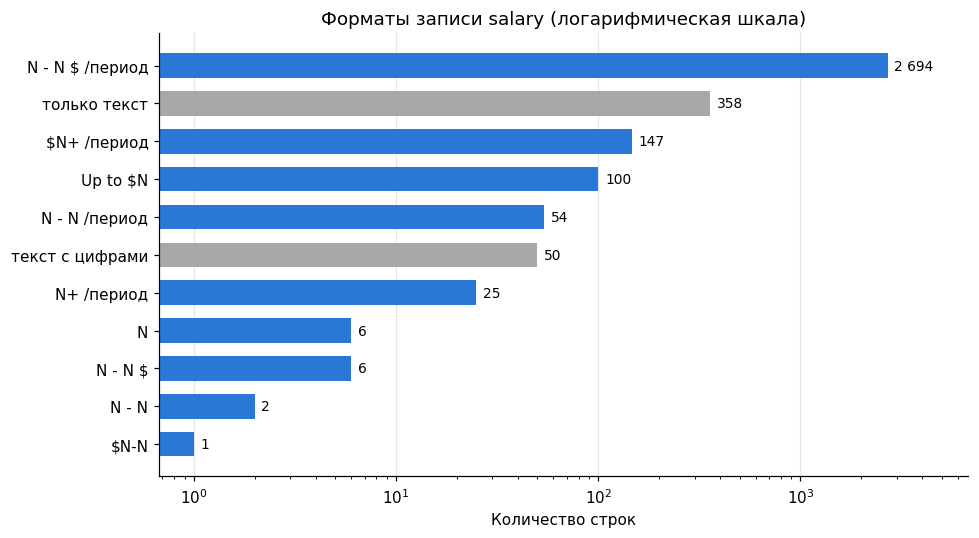

In [15]:
NUM = r'\d[\d,]*(?:\.\d+)?'
PERIOD = r'(?:\s*/\s*(?P<period>hour|week|month|year))'
CUR = r'\s*\$?\s*'
SALARY_PATTERNS = {
    'диапазон': re.compile(rf'{CUR}(?P<low>{NUM}){CUR}-{CUR}(?P<high>{NUM}){CUR}(?:{PERIOD}|$)', re.I),
    'до (Up to)': re.compile(rf'Up to{CUR}(?P<low>{NUM}){CUR}(?:{PERIOD}|$)', re.I),
    'от (N+)': re.compile(rf'{CUR}(?P<low>{NUM})\+{CUR}(?:{PERIOD}|$)', re.I),
    'одно значение': re.compile(rf'{CUR}(?P<low>{NUM}){CUR}(?:{PERIOD}|$)', re.I),
}


def parse_salary(text):

    for name, pattern in SALARY_PATTERNS.items():
        m = pattern.match(text)
        if m:
            template = re.sub(NUM, 'N', m.group(0).strip())
            template = re.sub(r'/\s*(hour|week|month|year)', '/период', template, flags=re.I)
            d = m.groupdict()
            period = d['period'].lower() if d.get('period') else None
            return name, re.sub(r'\s+', ' ', template), d['low'], d.get('high'), period
    if not re.search(r'\w', text):
        return 'пусто', None, None, None, None
    kind = 'текст с цифрами' if re.search(r'\d', text) else 'только текст'
    return kind, kind, None, None, None


salary_text = clean_text(df['salary'].dropna())
salary_parts = pd.DataFrame(salary_text.map(parse_salary).tolist(), index=salary_text.index,
                            columns=['salary_kind', 'salary_template', 'low', 'high', 'salary_period'])
print('Значений в salary (без NaN):', len(salary_text))
display(salary_parts['salary_kind'].value_counts().to_frame('строк'))
display(salary_text[salary_parts['salary_kind'].eq('текст с цифрами')].str[:70].value_counts().head(6).to_frame('строк'))

template_counts = salary_parts['salary_template'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
colors = [C_MUTED if 'текст' in name else C_MAIN for name in template_counts.index]
ax.barh(template_counts.index, template_counts.values, color=colors, height=0.65)
ax.set_xscale('log')
ax.set_title('Форматы записи salary (логарифмическая шкала)')
ax.set_xlabel('Количество строк')
ax.grid(axis='y', visible=False)
for y, v in enumerate(template_counts.values):
    ax.text(v * 1.08, y, f'{v:,}'.replace(',', ' '), va='center', fontsize=9)
ax.set_xlim(right=template_counts.max() * 2.5)
plt.tight_layout()
plt.show()

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

Строк с суммой: 3035 | из них без периода: 115


,salary,минимальная граница зарплаты,максимальная граница зарплаты,период
36,"68,000.00 - 72,000.00 $ /year",68000.0,72000.0,year
9233,39.00 - 40.00 $ /hour,39.0,40.0,hour
964,"80,000.00 - 90,000.00 $ /year",80000.0,90000.0,year
7492,"65,000.00 - 70,000.00 $ /year",65000.0,70000.0,year
2916,20.00 - 22.00 $ /hour,20.0,22.0,hour
15114,"90,000.00 - 110,000.00 $ /year",90000.0,110000.0,year


,count,mean,median
период,,,
hour,1142,187.61,15.13
week,6,593.67,600.00
month,17,6048.41,4905.22
year,1755,59789.88,55000.00


,count,mean,median
период,,,
hour,1084,196.40,15.00
week,6,593.67,600.00
month,17,6048.41,4905.22
year,1687,58844.48,55000.00


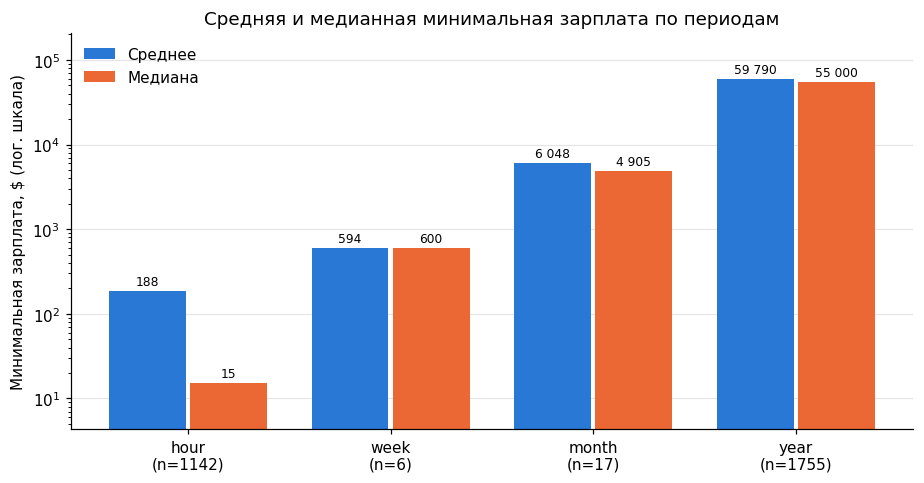

In [16]:
def to_float(s):
    return pd.to_numeric(s.str.replace(',', '', regex=False), errors='coerce').astype(float)


df_full['минимальная граница зарплаты'] = to_float(salary_parts['low'])
df_full['максимальная граница зарплаты'] = to_float(salary_parts['high'])
df_full['период'] = salary_parts['salary_period']

SAL_MIN, SAL_MAX, PERIOD_COL = 'минимальная граница зарплаты', 'максимальная граница зарплаты', 'период'
PERIOD_ORDER = ['hour', 'week', 'month', 'year']

with_amount = df_full[df_full[SAL_MIN].notna()]
print('Строк с суммой:', len(with_amount), '| из них без периода:', with_amount[PERIOD_COL].isna().sum())
display(with_amount[['salary', SAL_MIN, SAL_MAX, PERIOD_COL]].assign(salary=lambda d: d['salary'].str[:40]).sample(6, random_state=1))

stats = (with_amount.groupby(PERIOD_COL)[SAL_MIN].agg(['count', 'mean', 'median'])
         .reindex(PERIOD_ORDER).round(2))
display(stats)

no_dup = with_amount[~dup_extra.loc[with_amount.index]]
display(no_dup.groupby(PERIOD_COL)[SAL_MIN].agg(['count', 'mean', 'median']).reindex(PERIOD_ORDER).round(2))

x = np.arange(len(PERIOD_ORDER))
width = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars_mean = ax.bar(x - width / 2 - 0.01, stats['mean'], width, label='Среднее', color=C_MAIN)
bars_median = ax.bar(x + width / 2 + 0.01, stats['median'], width, label='Медиана', color=C_ACCENT)
ax.set_yscale('log')
ax.set_xticks(x, [f'{p}\n(n={stats.loc[p, "count"]:.0f})' for p in PERIOD_ORDER])
ax.set_ylabel('Минимальная зарплата, $ (лог. шкала)')
ax.set_title('Средняя и медианная минимальная зарплата по периодам')
ax.grid(axis='x', visible=False)
ax.legend(frameon=False)
for bars in (bars_mean, bars_median):
    ax.bar_label(bars, labels=[f'{h.get_height():,.0f}'.replace(',', ' ') for h in bars], fontsize=8, padding=2)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

,n,мин_граница_min,мин_граница_max,макс_граница_min,макс_граница_max
период,,,,,
hour,1142,0.0,100000.00,1.00,120000.0
week,6,12.0,1100.00,12.00,1500.0
month,17,1800.0,17688.94,1878.00,20971.0
year,1755,0.0,1000000.00,0.01,1000000.0


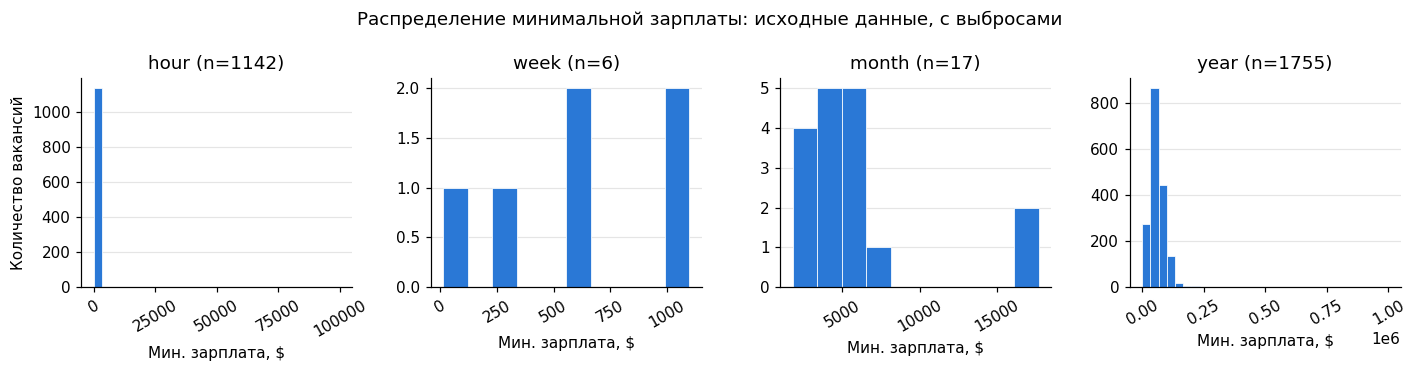

,n,выбросов,нижняя граница,верхняя граница,среднее,медиана
hour,1142.0,84.0,5.03,65.00,19.97,16.0
week,6.0,1.0,250.00,1100.00,710.00,600.0
month,17.0,2.0,1800.00,6833.33,4496.34,4900.0
year,1755.0,162.0,17000.00,215000.00,63385.92,60000.0


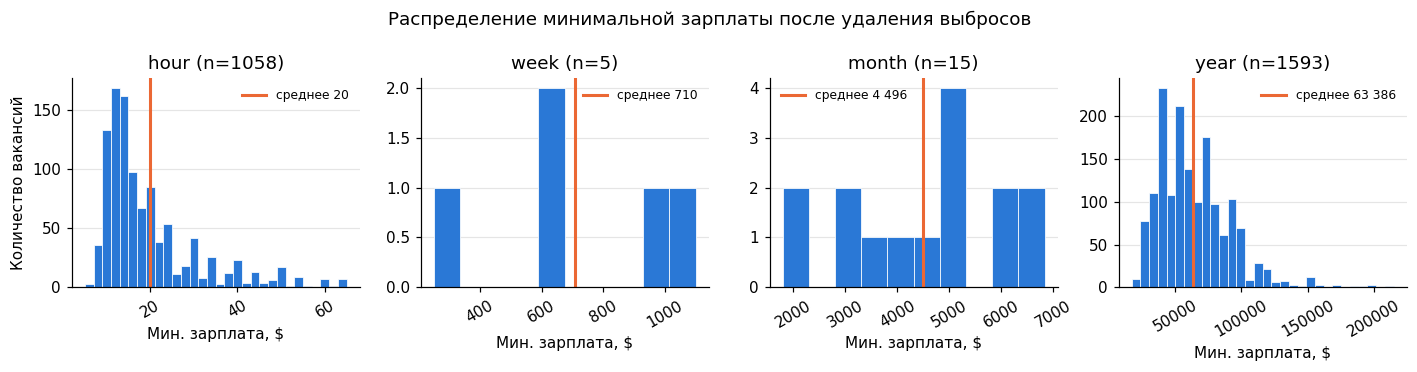

Строк без периода: 115 | период указан: 115 | оставлено пустым: 0


,восстановлено строк
период,
hour,65
week,0
month,0
year,50


,salary,минимальная граница зарплаты,найденный_период
18177,8.00,8.0,hour
9144,10.30 - 10.30 $,10.3,hour
3087,Up to $13.50,13.5,hour
7433,Up to $15.00,15.0,hour
13964,Up to $15.00,15.0,hour
2651,Up to $18.00,18.0,hour
3735,Up to $42.00,42.0,hour
21270,Up to $31500.00,31500.0,year
10034,Up to $40000.00,40000.0,year
5848,Up to $50000.00,50000.0,year


,salary,минимальная граница зарплаты,найденный_период


относительное расстояние: ответ для 2739 из 2920 строк, верно 97.4%; на строках без периода {'hour': 65, 'year': 50}, не выбрано 0
абсолютное расстояние: ответ для 2665 из 2920 строк, верно 93.2%; на строках без периода {'hour': 65, 'year': 36, 'month': 10}, не выбрано 4


минимальная граница зарплаты,hour,week,month,year
период,,,,
hour,1058,0,0,3
week,1,5,0,0
month,0,0,14,0
year,64,1,1,1592


In [17]:
known_period = with_amount[with_amount[PERIOD_COL].notna()]
spread = known_period.groupby(PERIOD_COL).agg(
    n=(SAL_MIN, 'count'),
    мин_граница_min=(SAL_MIN, 'min'), мин_граница_max=(SAL_MIN, 'max'),
    макс_граница_min=(SAL_MAX, 'min'), макс_граница_max=(SAL_MAX, 'max'),
).reindex(PERIOD_ORDER)
display(spread)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, period in zip(axes, PERIOD_ORDER):
    values = known_period.loc[known_period[PERIOD_COL].eq(period), SAL_MIN]
    ax.hist(values, bins=30 if len(values) > 50 else 10, color=C_MAIN, edgecolor='white', linewidth=0.5)
    ax.set_title(f'{period} (n={len(values)})')
    ax.set_xlabel('Мин. зарплата, $')
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelrotation=30)
axes[0].set_ylabel('Количество вакансий')
fig.suptitle('Распределение минимальной зарплаты: исходные данные, с выбросами')
plt.tight_layout()
plt.show()

def clean_bounds(values):
    logs = np.log(values[values > 0])
    q1, q3 = logs.quantile([0.25, 0.75])
    iqr = q3 - q1
    return np.exp(q1 - 1.5 * iqr), np.exp(q3 + 1.5 * iqr)


rows = {}
for period in PERIOD_ORDER:
    values = known_period.loc[known_period[PERIOD_COL].eq(period), SAL_MIN]
    low, high = clean_bounds(values)
    kept = values[values.between(low, high) & (values > 0)]
    rows[period] = {'n': len(values), 'выбросов': len(values) - len(kept),
                    'нижняя граница': kept.min(), 'верхняя граница': kept.max(),
                    'среднее': kept.mean(), 'медиана': kept.median()}
clean_stats = pd.DataFrame(rows).T
display(clean_stats.round(2))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, period in zip(axes, PERIOD_ORDER):
    r = clean_stats.loc[period]
    values = known_period.loc[known_period[PERIOD_COL].eq(period), SAL_MIN]
    values = values[values.between(r['нижняя граница'], r['верхняя граница'])]
    ax.hist(values, bins=30 if len(values) > 50 else 10, color=C_MAIN, edgecolor='white', linewidth=0.5)
    ax.axvline(r['среднее'], color=C_ACCENT, linewidth=2, label=f"среднее {r['среднее']:,.0f}".replace(',', ' '))
    ax.set_title(f'{period} (n={len(values)})')
    ax.set_xlabel('Мин. зарплата, $')
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelrotation=30)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('Количество вакансий')
fig.suptitle('Распределение минимальной зарплаты после удаления выбросов')
plt.tight_layout()
plt.show()
AMBIGUITY = 0.10
means = clean_stats['среднее']


def nearest_period(amount, relative=True):
    if amount <= 0 or not any(clean_stats['нижняя граница'].le(amount) & clean_stats['верхняя граница'].ge(amount)):
        return None
    distances = (np.log(means / amount).abs() if relative else (means - amount).abs()).sort_values()
    first, second = distances.iloc[0], distances.iloc[1]
    if second - first < AMBIGUITY * second:
        return None
    return distances.index[0]


no_period = with_amount[with_amount[PERIOD_COL].isna()]
filled = no_period[SAL_MIN].map(nearest_period).rename('период')
df_full['период восстановлен'] = False
df_full.loc[filled.dropna().index, PERIOD_COL] = filled.dropna()
df_full.loc[filled.dropna().index, 'период восстановлен'] = True

print('Строк без периода:', len(no_period), '| период указан:', filled.notna().sum(), '| оставлено пустым:', filled.isna().sum())
display(filled.value_counts().reindex(PERIOD_ORDER, fill_value=0).to_frame('восстановлено строк'))
result = no_period[['salary', SAL_MIN]].assign(salary=lambda d: d['salary'].str[:30], найденный_период=filled)
display(result.sort_values(SAL_MIN).iloc[np.linspace(0, len(result) - 1, 12).astype(int)])
display(result[result['найденный_период'].isna()].sort_values(SAL_MIN))

for relative, name in ((True, 'относительное расстояние'), (False, 'абсолютное расстояние')):
    predicted = known_period[SAL_MIN].map(lambda v: nearest_period(v, relative))
    answered = predicted.notna()
    accuracy = (predicted[answered] == known_period.loc[answered, PERIOD_COL]).mean()
    on_missing = no_period[SAL_MIN].map(lambda v: nearest_period(v, relative))
    print(f"{name}: ответ для {answered.sum()} из {len(known_period)} строк, верно {accuracy:.1%}; "
          f"на строках без периода {on_missing.value_counts().to_dict()}, не выбрано {on_missing.isna().sum()}")
predicted = known_period[SAL_MIN].map(nearest_period)
display(pd.crosstab(known_period[PERIOD_COL], predicted).reindex(index=PERIOD_ORDER, columns=PERIOD_ORDER, fill_value=0))

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

Уникальных значений (без учёта NaN): 39


,строк
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
NaN,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329


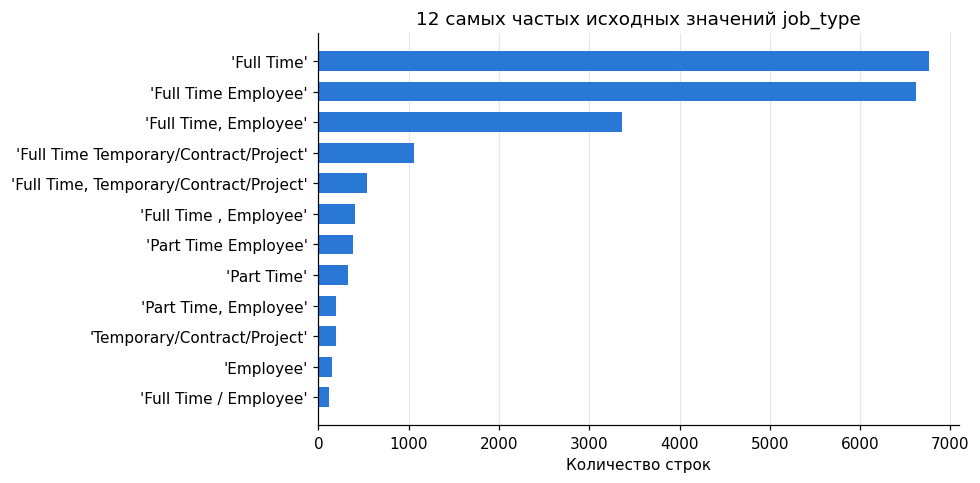

In [18]:
job_type_counts = df['job_type'].value_counts(dropna=False)
print('Уникальных значений (без учёта NaN):', df['job_type'].nunique())
display(job_type_counts.to_frame('строк'))
top = df['job_type'].value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([repr(v) for v in top.index], top.values, color=C_MAIN, height=0.65)
ax.set_title('12 самых частых исходных значений job_type')
ax.set_xlabel('Количество строк')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [19]:
def normalize_job_type(s):
    return (s.str.replace('\xa0', ' ', regex=False)
             .str.replace(r'^\s*Job Type\s+', '', regex=True)
             .str.replace(r'[,/>]+(?=\s)|(?<=Time)\s*/|(?<=Diem)\s*/', ' ', regex=True)
             .str.replace(r'\s+', ' ', regex=True)
             .str.strip())

df_full['job_type_norm'] = normalize_job_type(df_full['job_type'])
print('Значений было:', df_full['job_type'].nunique(), '| стало:', df_full['job_type_norm'].nunique())
display(df_full['job_type_norm'].value_counts(dropna=False).to_frame('строк'))

Значений было: 39 | стало: 15


,строк
job_type_norm,
Full Time Employee,10538
Full Time,6773
Full Time Temporary/Contract/Project,1654
NaN,1628
Part Time Employee,586
Part Time,330
Temporary/Contract/Project,193
Employee,148
Part Time Temporary/Contract/Project,57


Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

Значения, не подошедшие под шаблон: ['Exempt']
До заполнения: нет полноты — 1970 , нет типа — 8754 , из них job_type пуст полностью — 1628


тип занятости,Employee,Temporary/Contract/Project,Seasonal,Intern
полнота занятости,,,,
Full Time,19088,1847,0,5
Part Time,916,57,17,3
Per Diem,63,4,0,0


тип занятости,Employee,Temporary/Contract/Project,Seasonal,Intern
полнота занятости,,,,
Full Time,91.2,8.8,0.0,0.0
Part Time,92.2,5.7,1.7,0.3
Per Diem,94.0,6.0,0.0,0.0


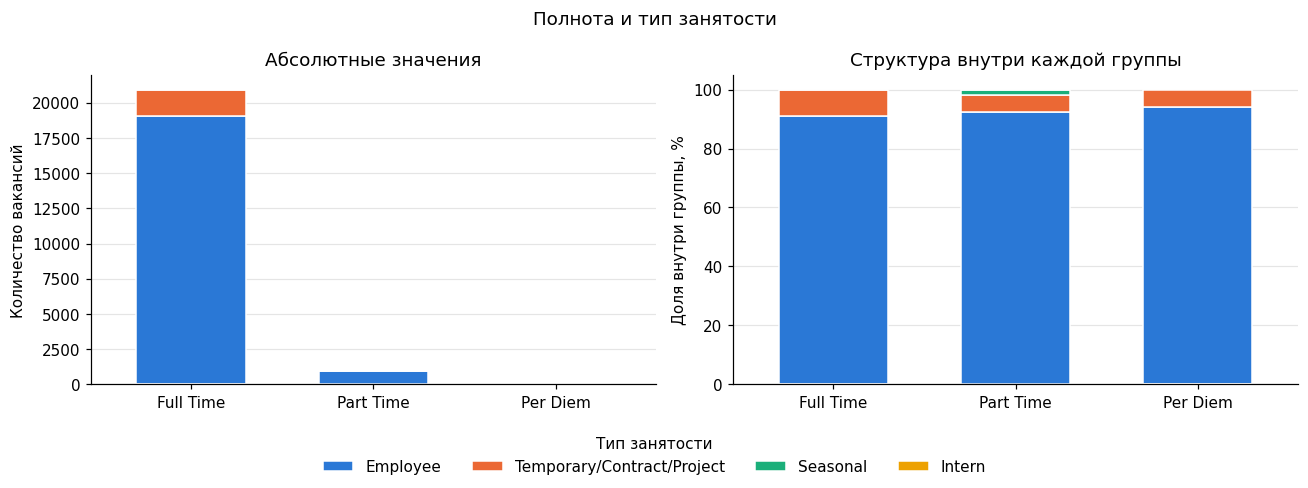

,location,city,state,zip,salary,минимальная граница зарплаты,максимальная граница зарплаты,период,job_type,полнота занятости,тип занятости
20061,Logistics Structure and Materi,Greer,SC,None,NaN,NaN,NaN,NaN,NaN,Full Time,Employee
2745,"Corpus Christi, TX",Corpus Christi,TX,None,NaN,NaN,NaN,NaN,"Full Time, Employee",Full Time,Employee
19128,"Beltsville, MD 20705",Beltsville,MD,20705,NaN,NaN,NaN,NaN,Full Time,Full Time,Employee
1015,"Dallas, TX",Dallas,TX,None,NaN,NaN,NaN,NaN,NaN,Full Time,Employee
17518,"Dallas, TX",Dallas,TX,None,NaN,NaN,NaN,NaN,Full Time,Full Time,Employee


In [20]:
JOB_TYPE = re.compile(r'^(?P<fullness>Full Time|Part Time|Per Diem)?\s*'
                      r'(?P<kind>Employee|Intern|Seasonal|Temporary/Contract/Project)?$')

parts = df_full['job_type_norm'].str.extract(JOB_TYPE)
print('Значения, не подошедшие под шаблон:',
      df_full.loc[df_full['job_type_norm'].notna() & parts['fullness'].isna() & parts['kind'].isna(), 'job_type_norm'].unique().tolist())

print('До заполнения: нет полноты —', parts['fullness'].isna().sum(), ', нет типа —', parts['kind'].isna().sum(),
      ', из них job_type пуст полностью —', df_full['job_type'].isna().sum())

df_full['полнота занятости'] = parts['fullness'].fillna('Full Time')
df_full['тип занятости'] = parts['kind'].fillna('Employee')

table = pd.crosstab(df_full['полнота занятости'], df_full['тип занятости'])
table = table.loc[table.sum(axis=1).sort_values(ascending=False).index,
                  table.sum(axis=0).sort_values(ascending=False).index]
display(table)
display((table.div(table.sum(axis=1), axis=0) * 100).round(1))

palette = dict(zip(table.columns, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
shares = table.div(table.sum(axis=1), axis=0) * 100
for ax, data, ylabel in ((axes[0], table, 'Количество вакансий'), (axes[1], shares, 'Доля внутри группы, %')):
    data.plot(kind='bar', stacked=True, ax=ax, color=[palette[c] for c in data.columns],
              width=0.6, edgecolor='white', linewidth=1, legend=False)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', labelrotation=0)
    ax.grid(axis='x', visible=False)
axes[0].set_title('Абсолютные значения')
axes[1].set_title('Структура внутри каждой группы')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Тип занятости', frameon=False, ncol=4, loc='lower center')
fig.suptitle('Полнота и тип занятости')
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

display(df_full[['location', 'city', 'state', 'zip', 'salary', SAL_MIN, SAL_MAX, PERIOD_COL,
                 'job_type', 'полнота занятости', 'тип занятости']]
        .assign(location=lambda d: d['location'].str[:30], salary=lambda d: d['salary'].str[:30])
        .sample(5, random_state=11))

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.